# PhishGuard: Multi-Source Email Threat Classification
## Phase 3: Exploratory Data Analysis (EDA) and Visualization

This notebook performs exploratory data analysis on the standardized, merged multi-source email threat dataset (`data/processed/cleaned_phishing_data.csv`).

### Objectives:
1. Inspect dataset structure, schema, and completeness.
2. Analyze target variable distribution (Legitimate vs. Phishing).
3. Engineer text length metrics (`email_length` and `word_count`) and investigate skewness.
4. Extract and compare the top 20 vocabulary keywords between threat and benign classes.
5. Export report-ready figures to `docs/assets/`.


In [1]:
import os
from pathlib import Path
import re
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import CountVectorizer

# Configure plotting aesthetics
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
sns.set_theme(style="whitegrid", font_scale=1.1)
plt.rcParams['figure.dpi'] = 300
plt.rcParams['savefig.dpi'] = 300

# Setup asset export directory
ASSET_DIR = Path("../docs/assets")
ASSET_DIR.mkdir(parents=True, exist_ok=True)
print(f"Asset export directory ready: {ASSET_DIR.resolve()}")


Asset export directory ready: D:\PhishGuard\docs\assets


### 1. Data Ingestion & Integrity Verification
Load the preprocessed dataset and verify shape and schema.


In [2]:
DATA_PATH = Path("../data/processed/cleaned_phishing_data.csv")
print(f"Loading processed dataset from: {DATA_PATH}...")

df = pd.read_csv(DATA_PATH)

print(f"\nDataset Dimensions: {df.shape[0]:,} rows x {df.shape[1]} columns")
print("\nDataFrame Info:")
df.info()

print("\nFirst 5 Sample Records:")
display(df.head())


Loading processed dataset from: ..\data\processed\cleaned_phishing_data.csv...



Dataset Dimensions: 163,868 rows x 2 columns

DataFrame Info:
<class 'pandas.DataFrame'>
RangeIndex: 163868 entries, 0 to 163867
Data columns (total 2 columns):
 #   Column  Non-Null Count   Dtype
---  ------  --------------   -----
 0   text    163868 non-null  str  
 1   label   163868 non-null  int64
dtypes: int64(1), str(1)
memory usage: 2.5 MB

First 5 Sample Records:


,text,label
0,"Buck up, your troubles caused by small dimensi...",1
1,Upgrade your sex and pleasures with these tech...,1
2,>+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+...,1
3,Would anyone object to removing .so from this ...,0
4,WelcomeFastShippingCustomerSupport\nhttp://7iw...,1


### 2. Feature Engineering & Statistical Summaries
Calculate text-level descriptive features:
- `email_length`: Character length of the email text.
- `word_count`: Number of whitespace-separated tokens.


In [3]:
# Compute email length (character count) and word count
df['email_length'] = df['text'].astype(str).str.len()
df['word_count'] = df['text'].astype(str).str.split().str.len()

# Add human-readable label string for visualizations
df['class_name'] = df['label'].map({0: 'Legitimate (0)', 1: 'Phishing (1)'})

print("=== Overall Summary Statistics ===")
display(df[['email_length', 'word_count']].describe().map(lambda x: f"{x:,.2f}"))

print("\n=== Statistics Grouped by Class ===")
grouped_stats = df.groupby('class_name')[['email_length', 'word_count']].describe()
display(grouped_stats)


=== Overall Summary Statistics ===


,email_length,word_count
count,"163,868.00","163,868.00"
mean,"1,530.10",217.69
std,"16,289.14",692.17
min,1.00,1.00
25%,288.00,43.00
50%,638.00,99.00
75%,"1,601.00",236.00
max,"4,599,644.00","127,119.00"



=== Statistics Grouped by Class ===


email_length                                                \
                      count         mean           std  min    25%    50%   
class_name                                                                  
Legitimate (0)      78815.0  1851.454114   4639.200979  1.0  458.0  908.0   
Phishing (1)        85053.0  1232.324362  22160.473384  1.0  232.0  428.0   

                                  word_count                               \
                   75%        max      count        mean         std  min   
class_name                                                                  
Legitimate (0)  1808.0   299201.0    78815.0  280.679477  703.249561  1.0   
Phishing (1)    1259.0  4599644.0    85053.0  159.318249  676.532684  1.0   

                                              
                 25%    50%    75%       max  
class_name                                    
Legitimate (0)  68.0  138.0  285.0   45448.0  
Phishing (1)    33.0   67.0  199.0  127119.0

### 3. Visualization 1: Class Distribution
Assess balance between benign/legitimate emails and malicious phishing emails.


Saved: D:\PhishGuard\docs\assets\class_distribution.png


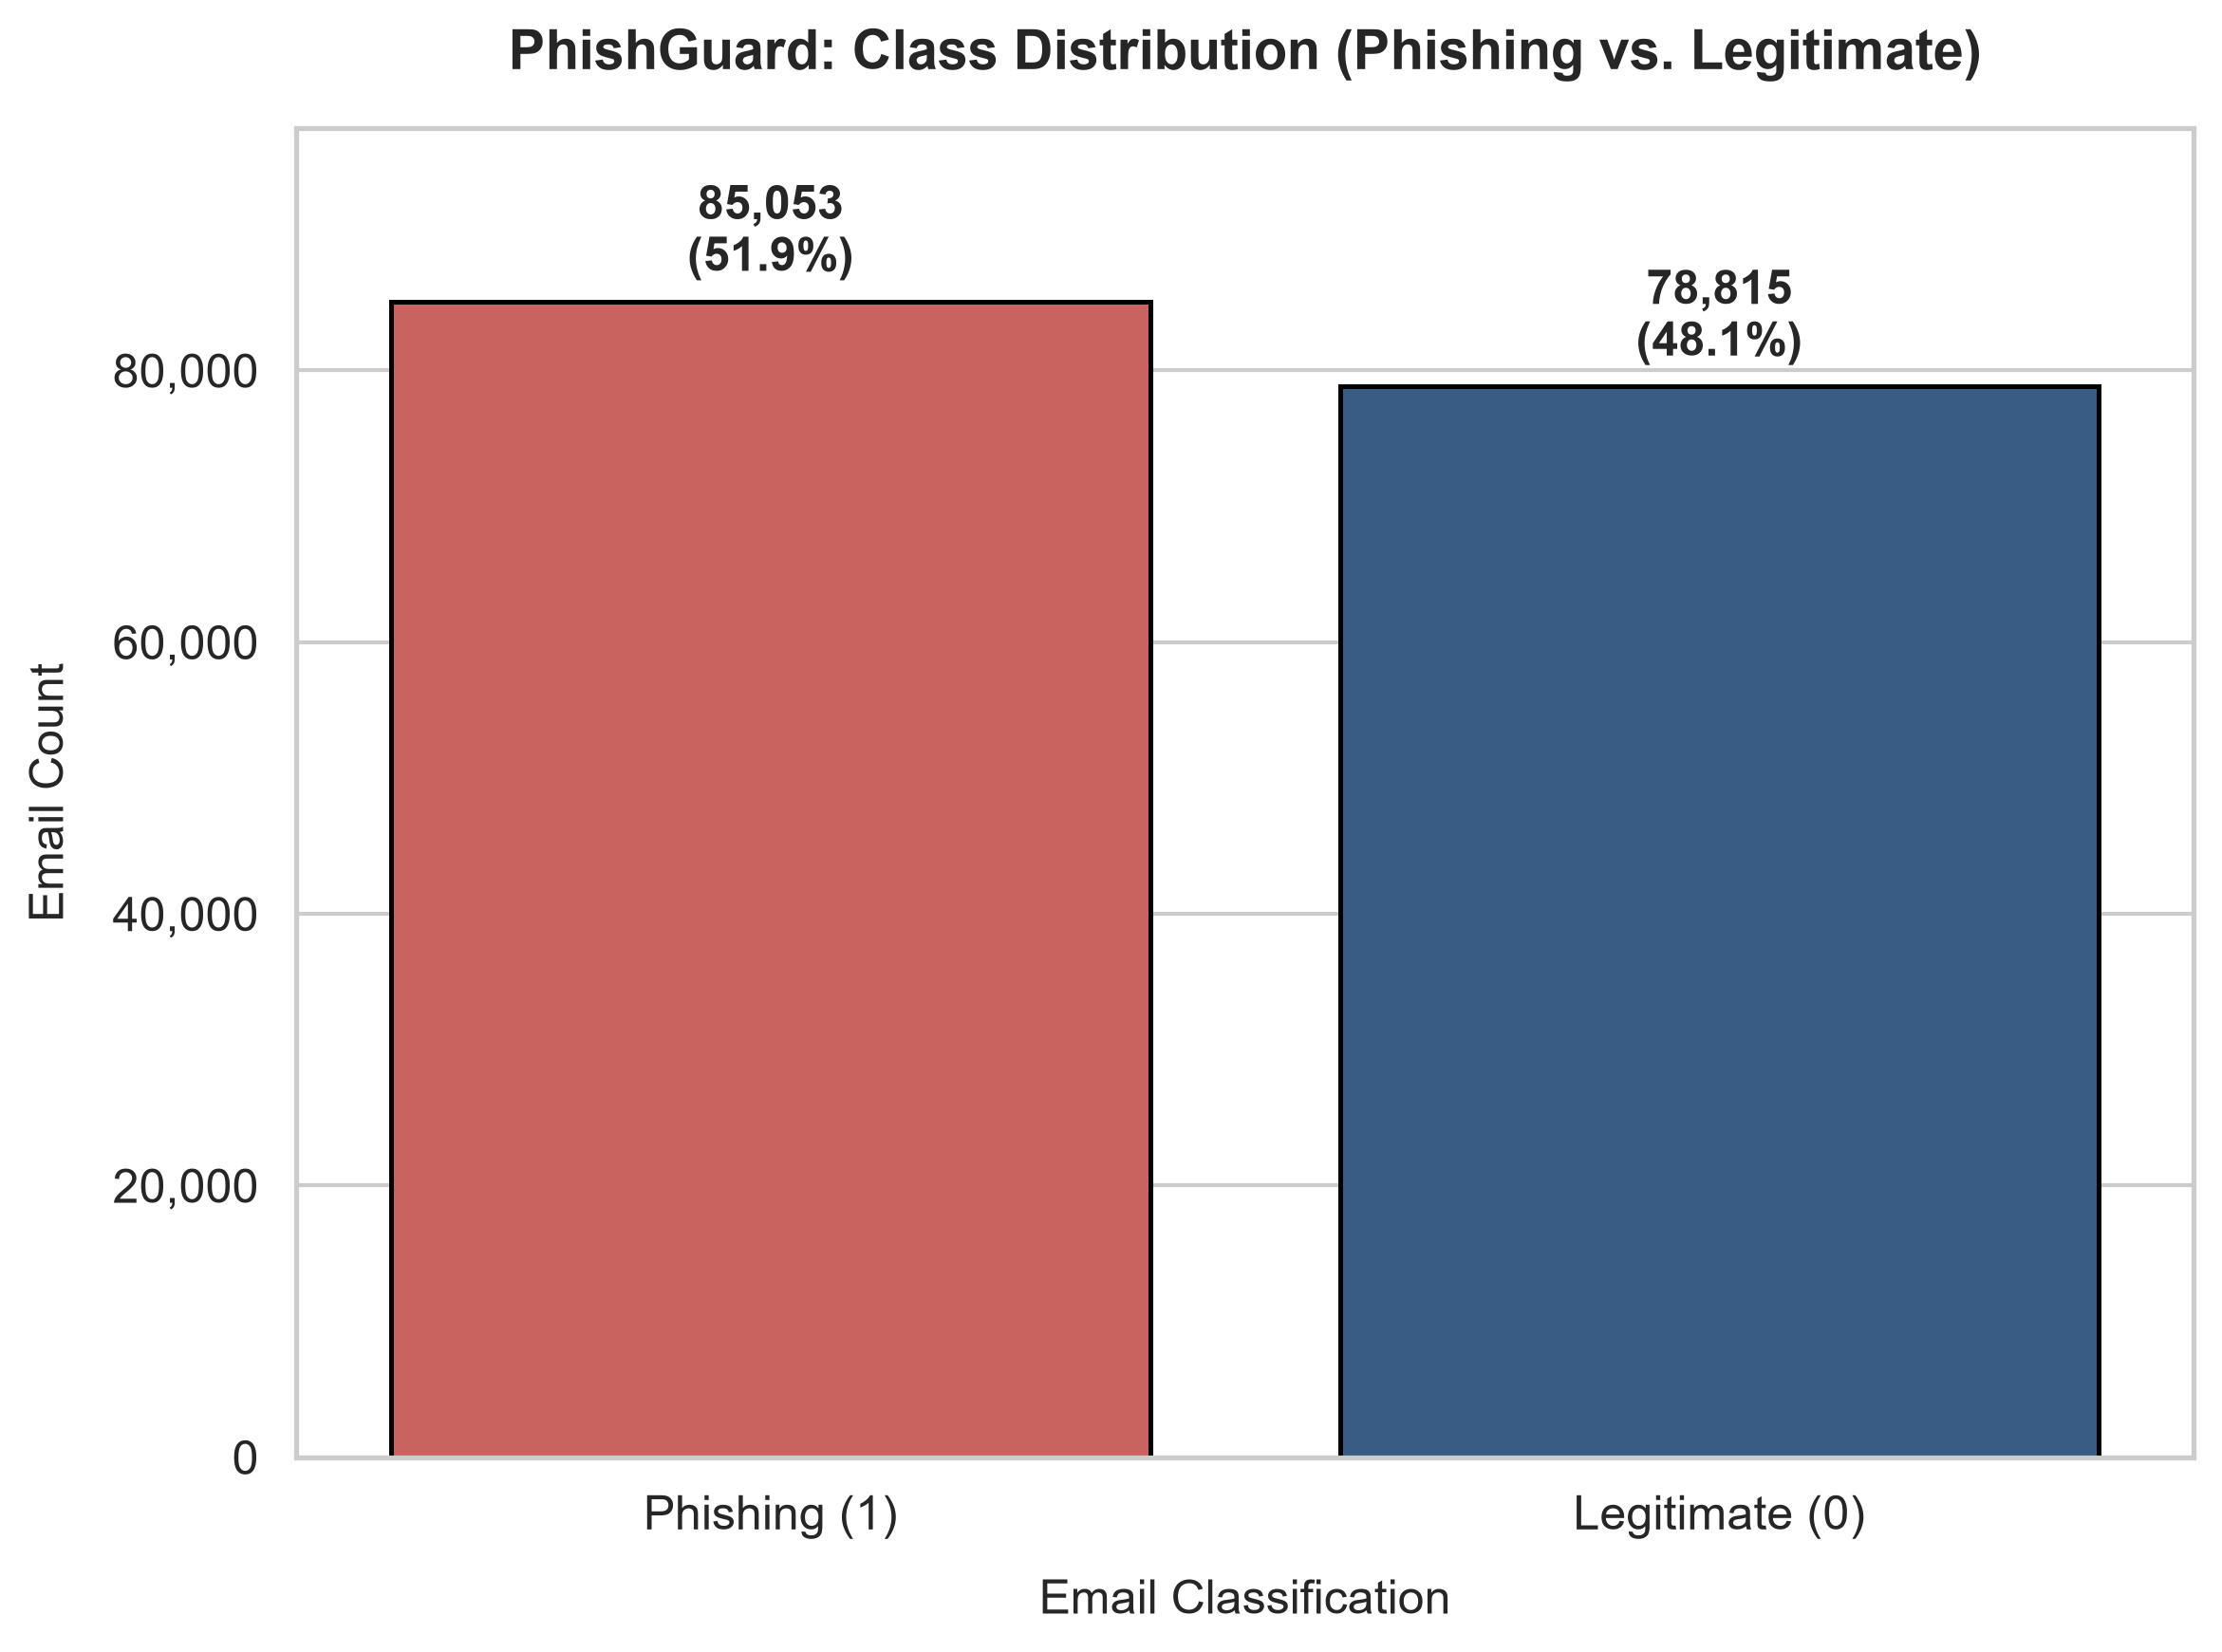

In [ ]:
fig, ax = plt.subplots(figsize=(8, 6))

palette = {'Legitimate (0)': '#2b5c8f', 'Phishing (1)': '#d9534f'}
counts = df['class_name'].value_counts()
percentages = df['class_name'].value_counts(normalize=True) * 100

sns.barplot(
    x=counts.index, 
    y=counts.values, 
    palette=palette,
    hue=counts.index,
    legend=False,
    edgecolor='black',
    linewidth=1.2,
    ax=ax
)

for i, (label_name, count) in enumerate(counts.items()):
    pct = percentages[label_name]
    ax.text(
        i, count + (counts.max() * 0.015), 
        f"{count:,}\n({pct:.1f}%)", 
        ha='center', va='bottom', 
        fontweight='bold', fontsize=12
    )

ax.set_title("PhishGuard: Class Distribution (Phishing vs. Legitimate)", fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel("Email Classification", fontsize=12, labelpad=10)
ax.set_ylabel("Email Count", fontsize=12, labelpad=10)
ax.set_ylim(0, counts.max() * 1.15)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, loc: f"{int(x):,}"))

plt.tight_layout()
dist_plot_path = ASSET_DIR / "class_distribution.png"
plt.savefig(dist_plot_path, dpi=300, bbox_inches='tight')
print(f"Saved: {dist_plot_path.resolve()}")
plt.show()


### 4. Visualization 2: Email Length Distribution (Log Scale)
Examine email length distribution across classes. Because email lengths range from short notices to long technical logs, a log scale is applied to resolve heavy skewness.


Saved: D:\PhishGuard\docs\assets\email_length_distribution.png


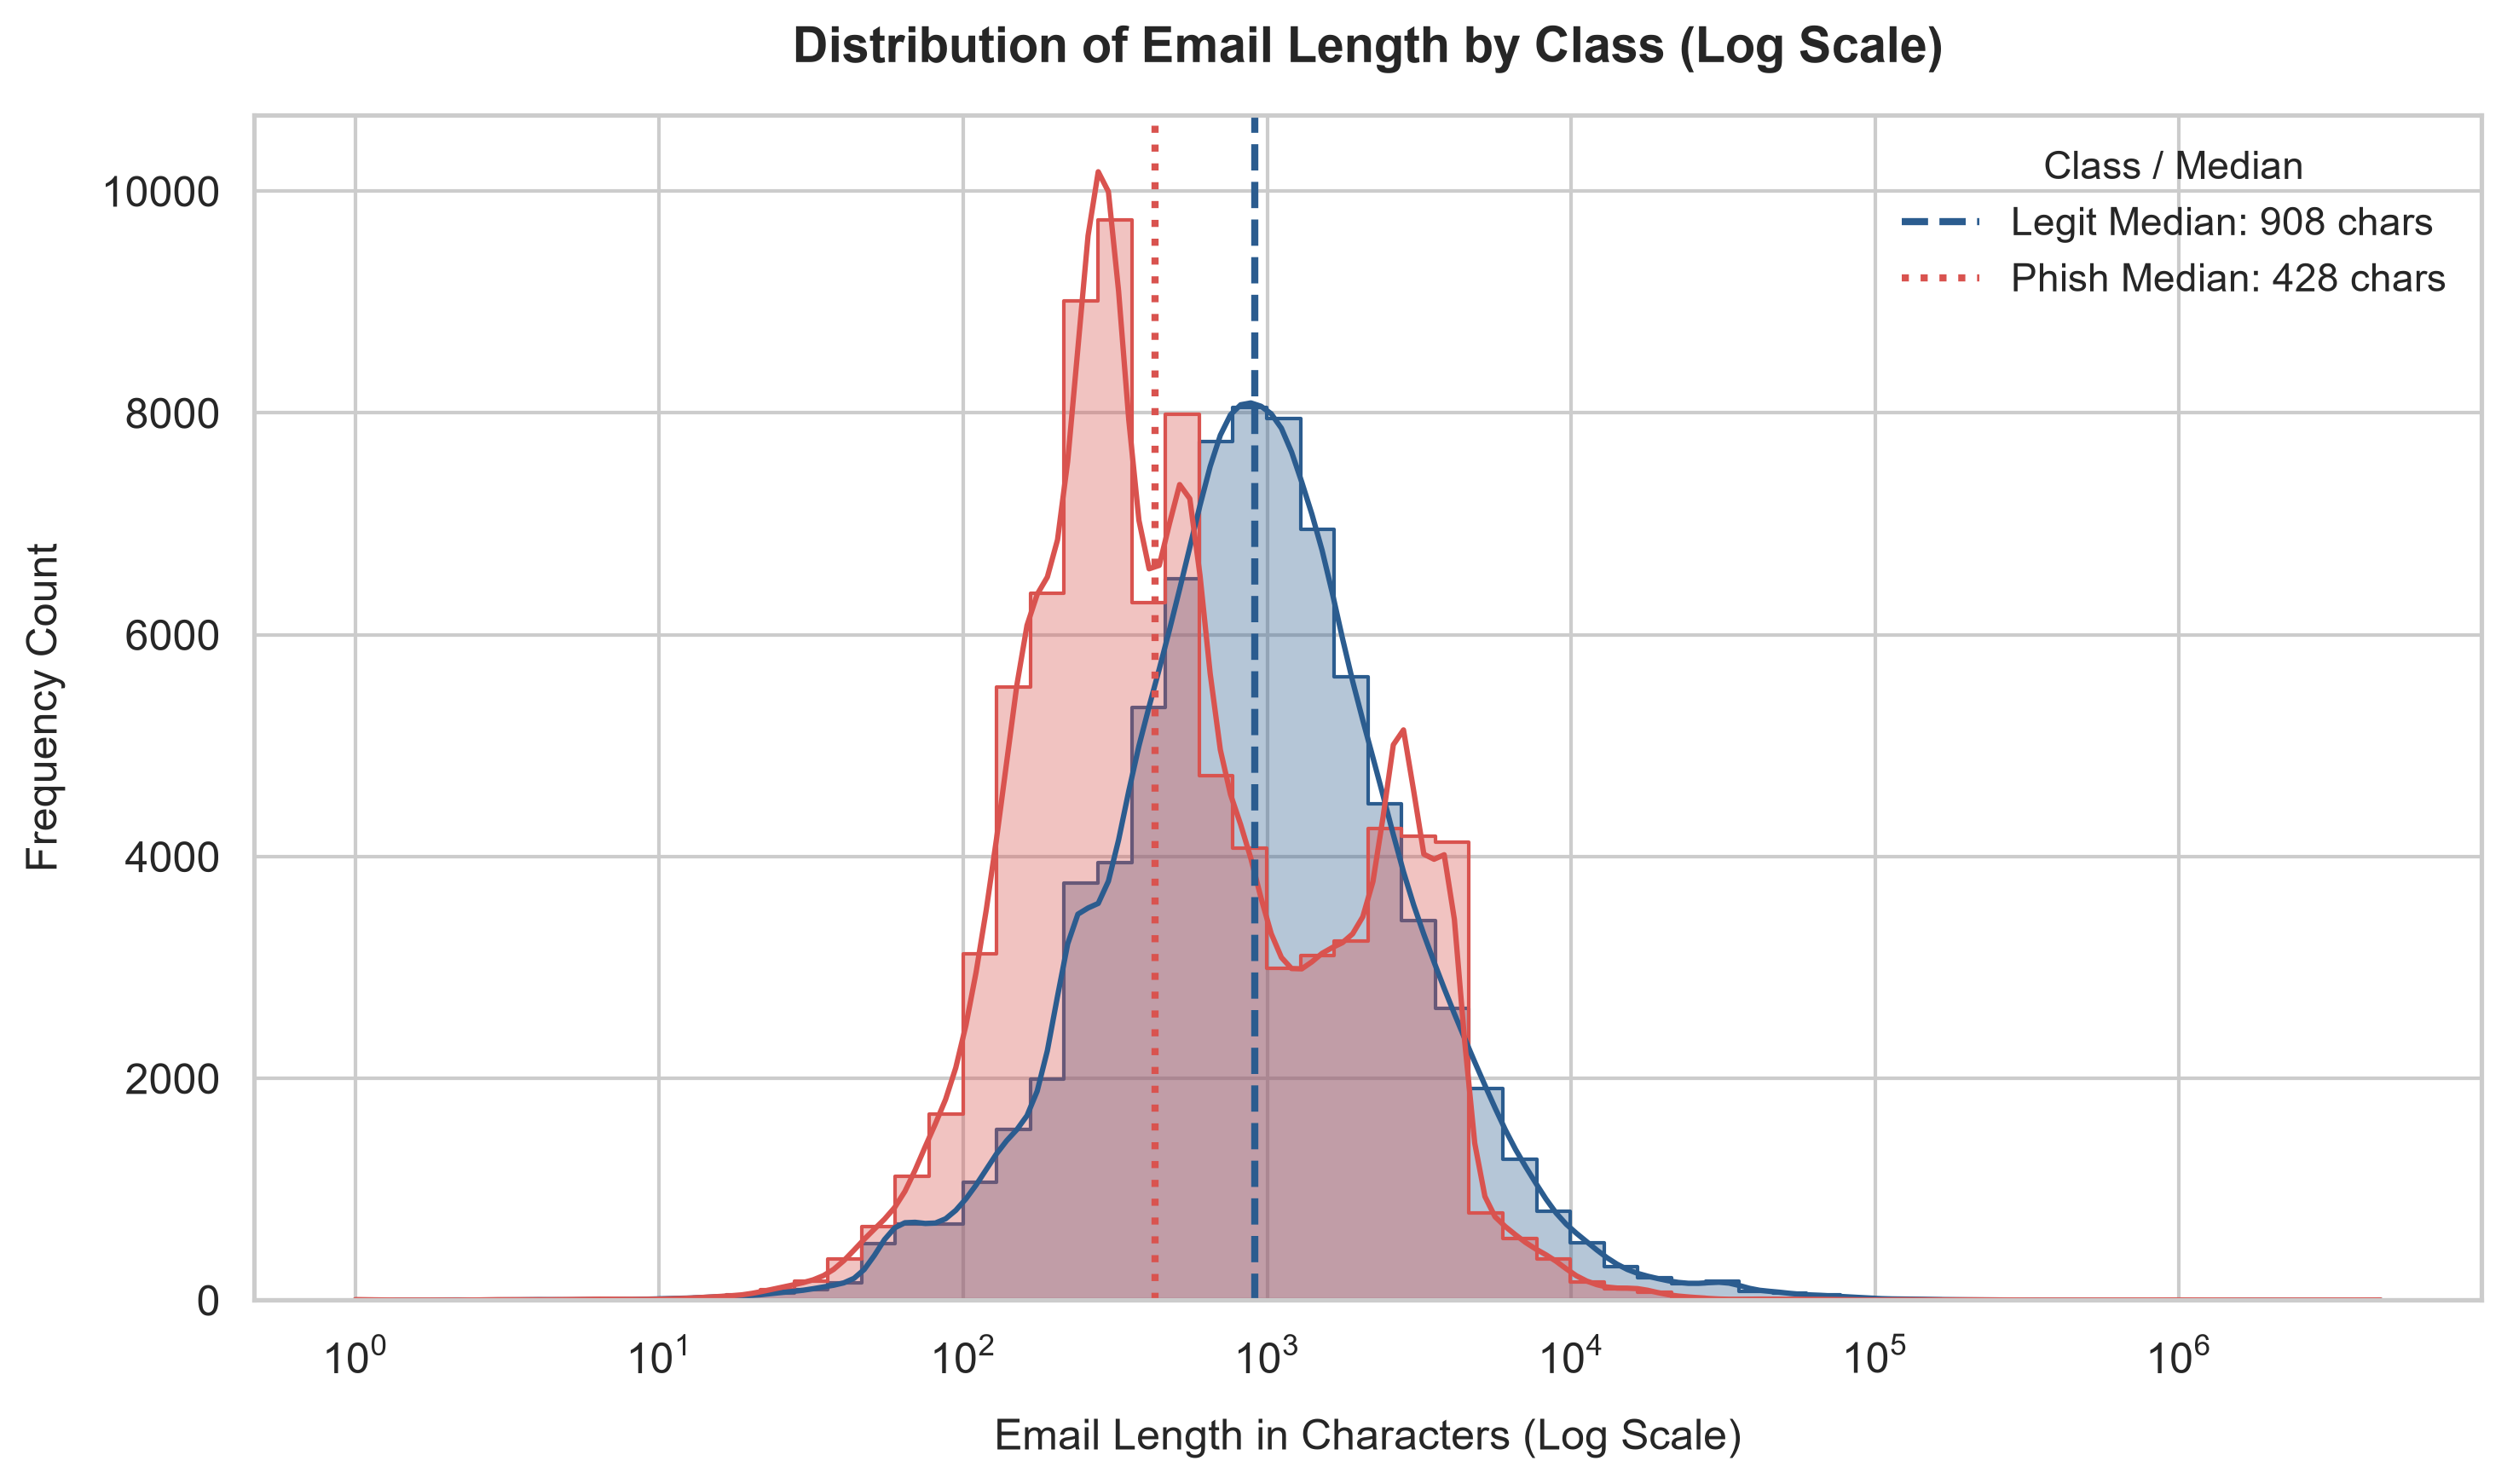

In [5]:
fig, ax = plt.subplots(figsize=(10, 6))

sns.histplot(
    data=df,
    x='email_length',
    hue='class_name',
    palette={'Legitimate (0)': '#2b5c8f', 'Phishing (1)': '#d9534f'},
    log_scale=True,
    kde=True,
    element='step',
    common_norm=False,
    bins=60,
    alpha=0.35,
    ax=ax
)

# Medians
med_legit = df[df['label'] == 0]['email_length'].median()
med_phish = df[df['label'] == 1]['email_length'].median()

ax.axvline(med_legit, color='#2b5c8f', linestyle='--', linewidth=2, label=f'Legit Median: {int(med_legit):,} chars')
ax.axvline(med_phish, color='#d9534f', linestyle=':', linewidth=2, label=f'Phish Median: {int(med_phish):,} chars')

ax.set_title("Distribution of Email Length by Class (Log Scale)", fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel("Email Length in Characters (Log Scale)", fontsize=12, labelpad=10)
ax.set_ylabel("Frequency Count", fontsize=12, labelpad=10)
ax.legend(title="Class / Median", fontsize=11, title_fontsize=11)

plt.tight_layout()
length_plot_path = ASSET_DIR / "email_length_distribution.png"
plt.savefig(length_plot_path, dpi=300, bbox_inches='tight')
print(f"Saved: {length_plot_path.resolve()}")
plt.show()


### 5. Visualization 3: Top 20 Most Frequent Words (Phishing vs. Legitimate)
Analyze the most prominent unigrams in each class, excluding standard English stop words.


Extracting top 20 words for Legitimate emails...


Extracting top 20 words for Phishing emails...


Saved: D:\PhishGuard\docs\assets\top_words_comparison.png


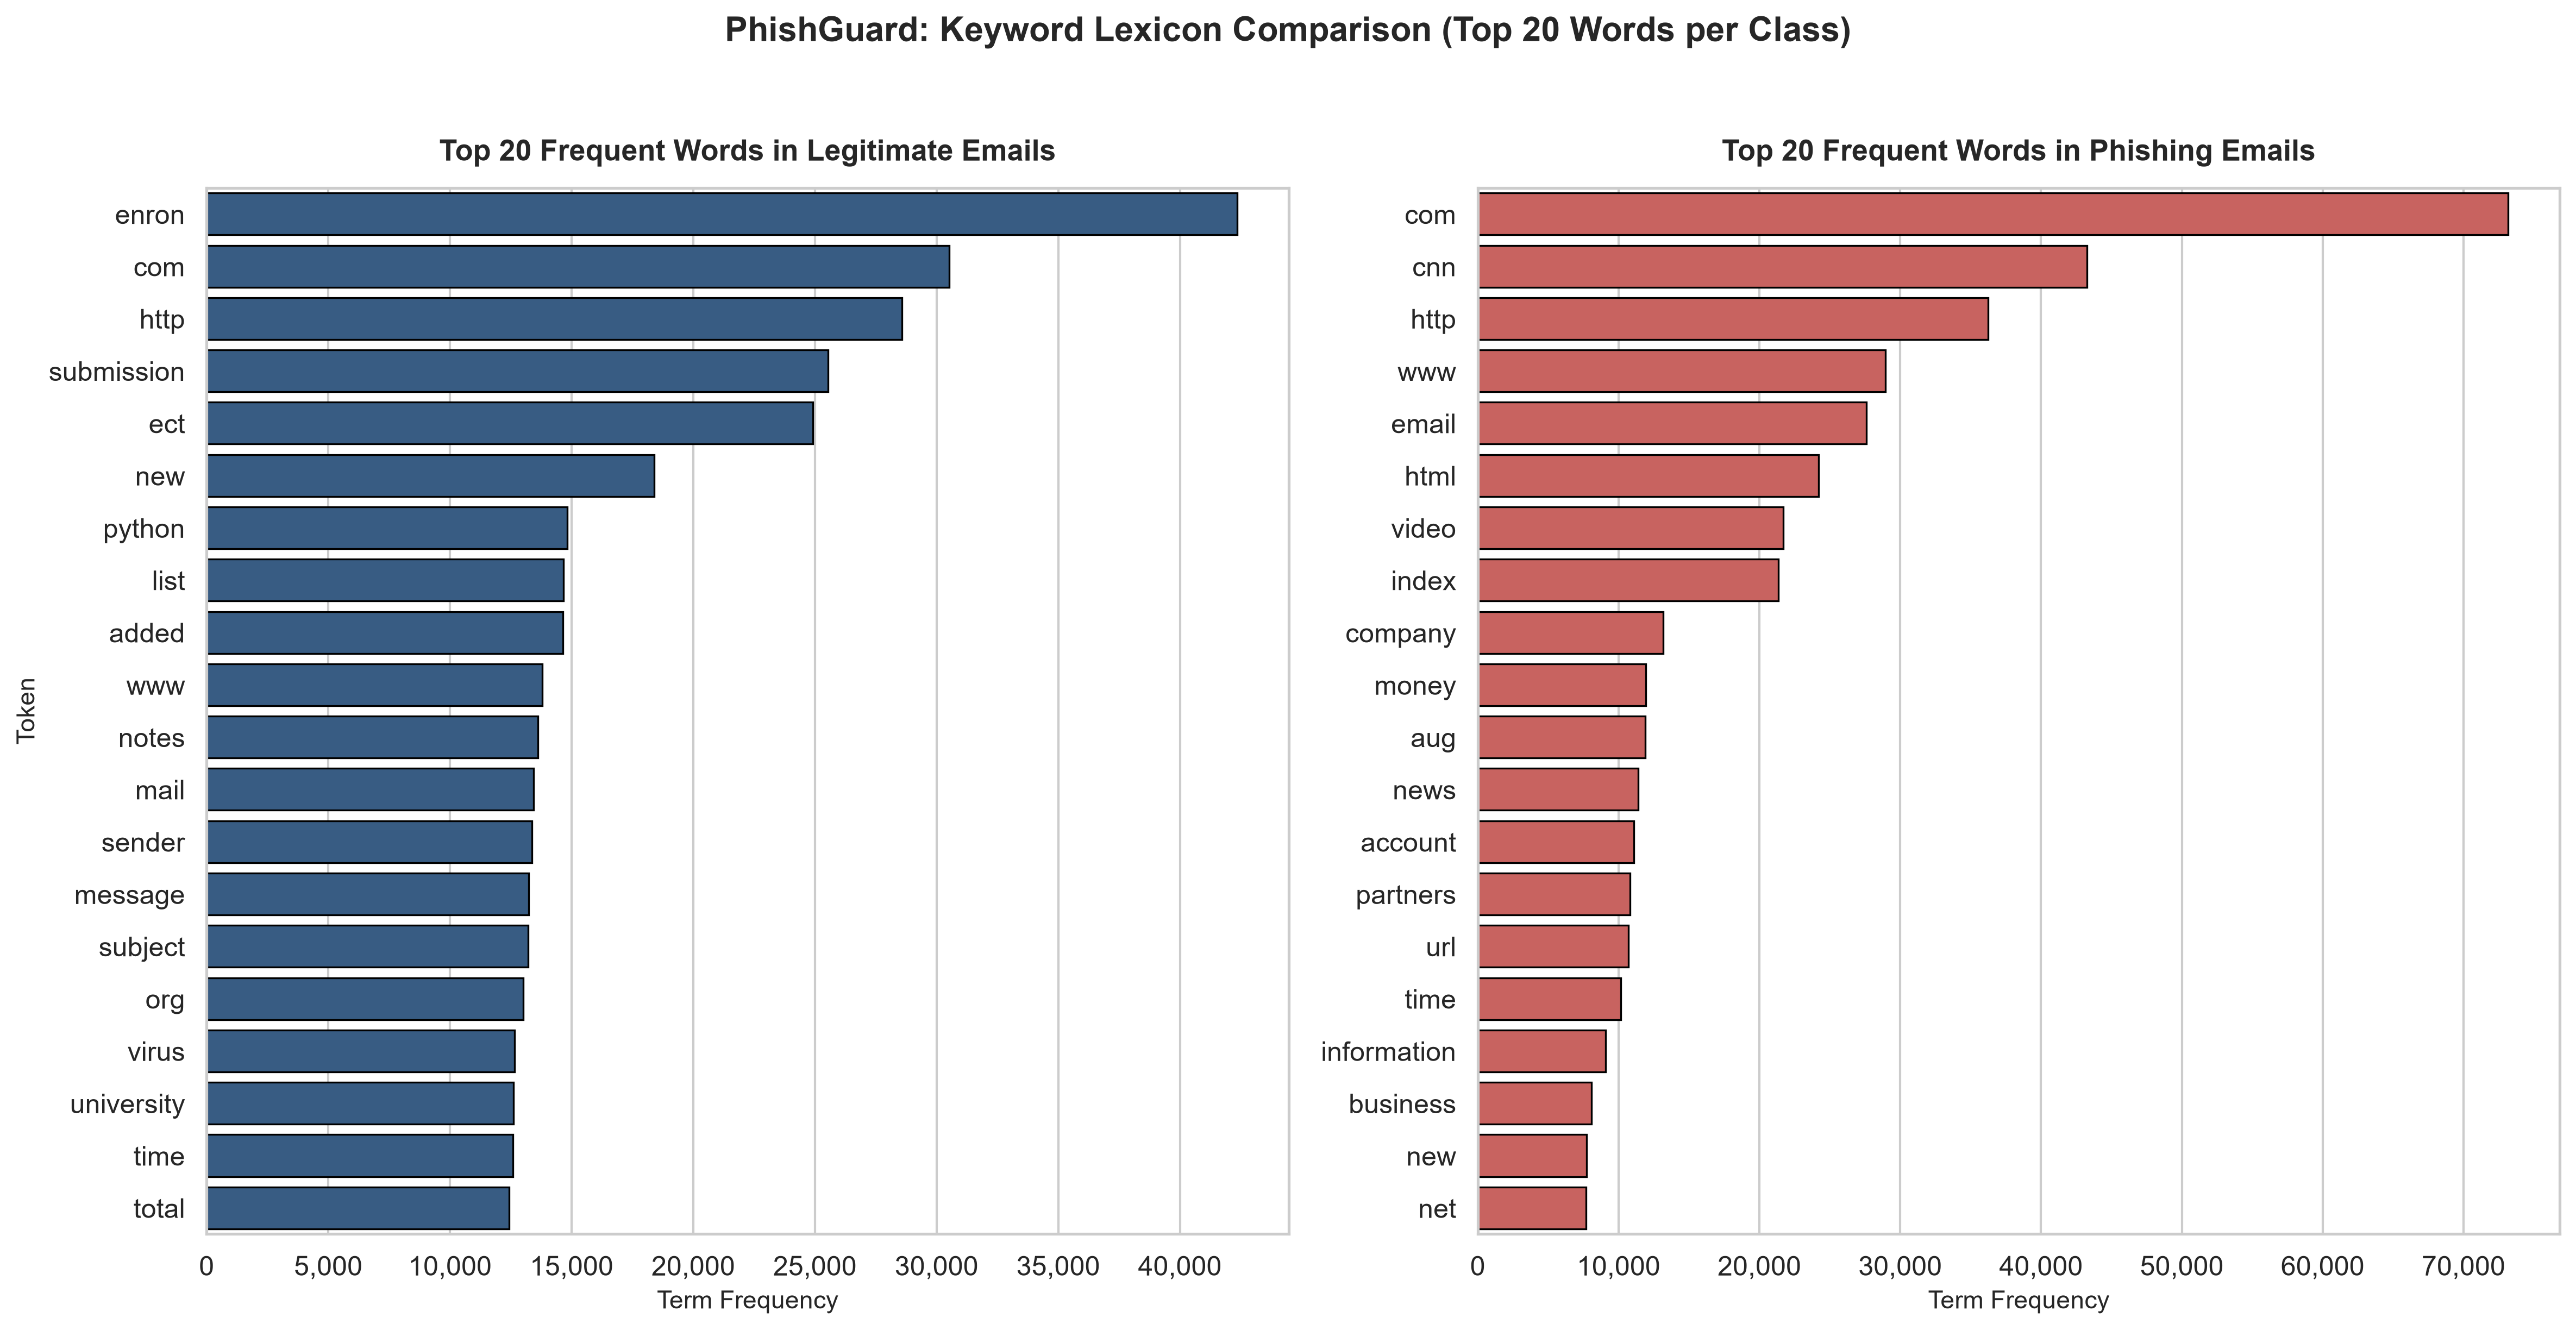

In [6]:
def get_top_n_words(corpus, n=20, sample_size=30000):
    """Extract top N frequent unigrams excluding English stop words."""
    if len(corpus) > sample_size:
        corpus = corpus.sample(n=sample_size, random_state=42)
    
    vec = CountVectorizer(
        stop_words='english',
        token_pattern=r'(?u)\b[a-zA-Z]{3,}\b',
        max_features=5000
    )
    bag_of_words = vec.fit_transform(corpus.astype(str))
    sum_words = bag_of_words.sum(axis=0)
    words_freq = [(word, int(sum_words[0, idx])) for word, idx in vec.vocabulary_.items()]
    words_freq = sorted(words_freq, key=lambda x: x[1], reverse=True)
    return pd.DataFrame(words_freq[:n], columns=['word', 'frequency'])

print("Extracting top 20 words for Legitimate emails...")
top_legit = get_top_n_words(df[df['label'] == 0]['text'], n=20)

print("Extracting top 20 words for Phishing emails...")
top_phish = get_top_n_words(df[df['label'] == 1]['text'], n=20)

fig, axes = plt.subplots(1, 2, figsize=(16, 8), sharey=False)

# Legitimate words plot
sns.barplot(
    data=top_legit,
    x='frequency',
    y='word',
    color='#2b5c8f',
    edgecolor='black',
    linewidth=0.8,
    ax=axes[0]
)
axes[0].set_title("Top 20 Frequent Words in Legitimate Emails", fontsize=13, fontweight='bold', pad=12)
axes[0].set_xlabel("Term Frequency", fontsize=11)
axes[0].set_ylabel("Token", fontsize=11)
axes[0].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, loc: f"{int(x):,}"))

# Phishing words plot
sns.barplot(
    data=top_phish,
    x='frequency',
    y='word',
    color='#d9534f',
    edgecolor='black',
    linewidth=0.8,
    ax=axes[1]
)
axes[1].set_title("Top 20 Frequent Words in Phishing Emails", fontsize=13, fontweight='bold', pad=12)
axes[1].set_xlabel("Term Frequency", fontsize=11)
axes[1].set_ylabel("", fontsize=11)
axes[1].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, loc: f"{int(x):,}"))

plt.suptitle("PhishGuard: Keyword Lexicon Comparison (Top 20 Words per Class)", fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()

words_plot_path = ASSET_DIR / "top_words_comparison.png"
plt.savefig(words_plot_path, dpi=300, bbox_inches='tight')
print(f"Saved: {words_plot_path.resolve()}")
plt.show()


### 6. Key Findings & Insights for Modeling (Phase 4)
- **Class Balance**: The merged dataset exhibits a near 50/50 balance (51.9% Phishing vs 48.1% Legitimate), removing the need for aggressive synthetic rebalancing (SMOTE).
- **Length Profiling**: Phishing emails show distinct length characteristics compared to regular enterprise communications (e.g., concise urgency prompts vs long thread histories).
- **Vocabulary Discrepancies**: Phishing vocabulary heavily emphasizes action words, security assertions, urgency, and credentials, whereas legitimate emails focus on routine topics, scheduling, and standard operational terminology.
- **Readiness for Phase 4**: Text data is well-formed for vectorization (TF-IDF) and machine learning classification.
